In [16]:
#Import the libraies 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

In [10]:
#Read the cleanfiles files 
International_students=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /education-spending/clean_international_students.csv")
Goverment_spending=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /education-spending/clean_government_spending.csv")
Clean_eu_students=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /education-spending/clean_eu_students.csv")
economic=pd.read_csv("/Users/jahaankachwala/Downloads/Projects /Global Salary Data/economic_indicators_clean.csv")

In [11]:
#Economic Indicators 
print("Indicators in economic file:", economic["indicator_name"].unique())
indicator = economic["indicator_name"].iloc[0]
economic = economic[economic["indicator_name"] == indicator]
print("Using indicator:", indicator, "\n")
 
# Wide (one column per year) -> long format
econ_years = [c for c in economic.columns if str(c).isdigit()]
econ_long = economic.melt(id_vars=["country_name", "country_code"], value_vars=econ_years,
                          var_name="year", value_name="econ_value")
econ_long["year"] = econ_long["year"].astype(int)
econ_long = econ_long.dropna(subset=["econ_value"])
 
Goverment_spending = Goverment_spending.dropna(subset=["country_code"])

Indicators in economic file: ['GDP (current US$)']
Using indicator: GDP (current US$) 



Countries reporting per year (check coverage is stable):
year
2013    33
2014    32
2015    33
2016    36
2017    36
2018    36
2019    36
2020    35
2021    36
2022    35
2023    34
2024    35
Name: country, dtype: int64 

      international_students  total_growth_pct
year                                          
2013               1462521.0               NaN
2014               1537278.0               5.1
2015               1609860.0               4.7
2016               3009675.0              87.0
2017               3175236.0               5.5
2018               3355486.0               5.7
2019               3363581.0               0.2
2020               3196642.0              -5.0
2021               3355809.0               5.0
2022               3339123.0              -0.5
2023               3578082.0               7.2
2024               3745228.0               4.7 

Growth in students by origin, 2013 -> 2024 (%):
from_india     517.6
from_africa    261.6
from_eu27      170.6
from_

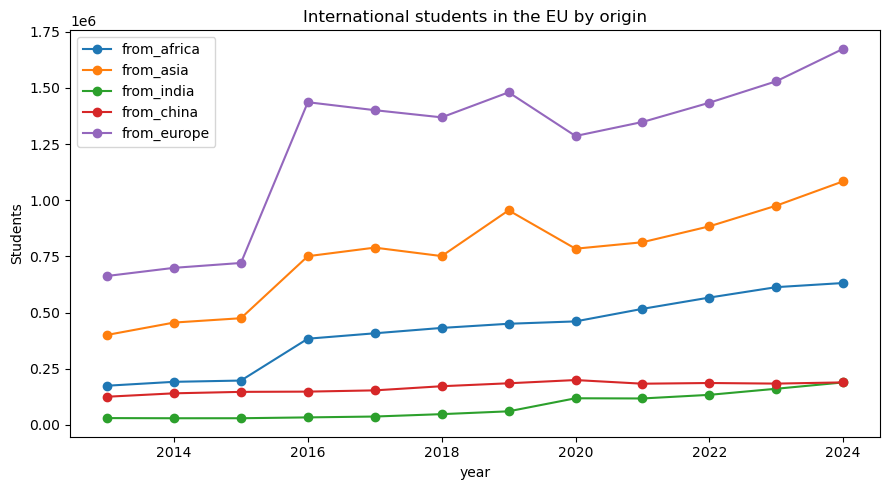

In [20]:
#Checking for upward trend of international students 
origin_cols = ["from_eu27", "from_europe", "from_asia", "from_africa", "from_china", "from_india"]
yearly = International_students.groupby("year")[["international_students"] + origin_cols].sum()
 
print("Countries reporting per year (check coverage is stable):")
print(International_students.groupby("year")["country"].nunique(), "\n")
 
yearly["total_growth_pct"] = yearly["international_students"].pct_change() * 100
print(yearly[["international_students", "total_growth_pct"]].round(1), "\n")
 
first, last = yearly.index.min(), yearly.index.max()
growth = ((yearly.loc[last, origin_cols] / yearly.loc[first, origin_cols] - 1) * 100).sort_values(ascending=False)
print(f"Growth in students by origin, {first} -> {last} (%):")
print(growth.round(1), "\n")
 
shares = yearly[origin_cols].div(yearly["international_students"], axis=0) * 100
print("Share of total international students (%):")
print(shares.round(1), "\n")
 
yearly[["from_africa", "from_asia", "from_india", "from_china", "from_europe"]].plot(marker="o", figsize=(9, 5))
plt.title("International students in the EU by origin")
plt.ylabel("Students")
plt.tight_layout()
plt.show()

africa: spending matched 29/29 | economic matched 29/29
south_asia: spending matched 8/8 | economic matched 8/8
eu: spending matched 27/27 | economic matched 27/27

Years in analysis table: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]

Region as % of EU level, by year (EU = 100):
      spend_africa_pct_of_eu  econ_africa_pct_of_eu  \
year                                                  
2013                    80.0                    8.4   
2014                    82.5                    8.6   
2015                    93.6                   10.3   
2016                    88.9                   10.4   
2017                    87.0                   11.7   
2018                    93.0                   10.9   
2019                    92.7                    9.4   
2020                    89.4                    9.8   
2021                    90.1                    9.7   
2022                    88.7                   10.4   
2023                     NaN   

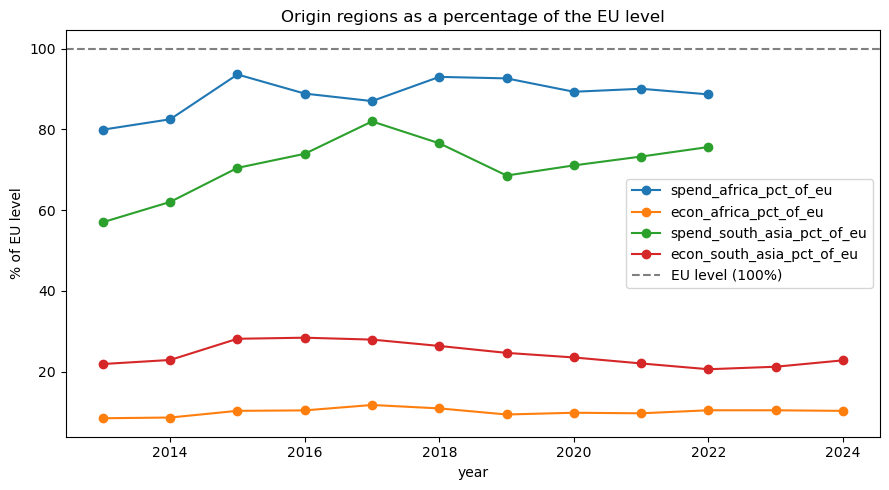


Cross-country (n=202): spending vs economic indicator -> Pearson r=0.03 (p=0.670), Spearman rho=0.01 (p=0.864)


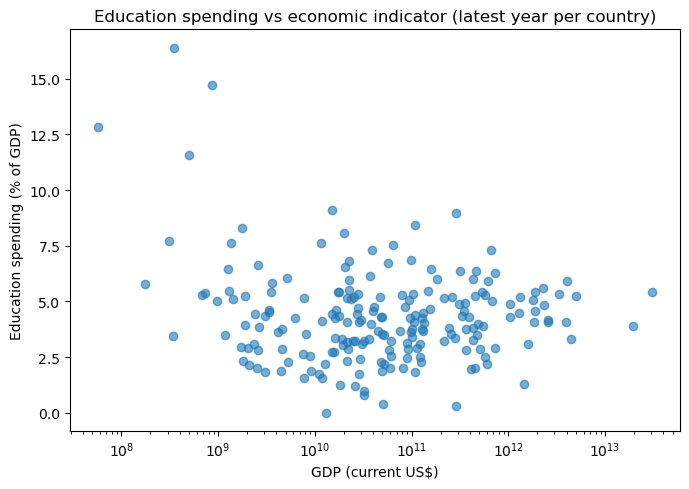

In [22]:
#Lower Education spending leading to migrartion in europe 
africa = ["DZA", "BEN", "BWA", "BFA", "CMR", "CIV", "EGY", "ETH", "GHA", "KEN", "LSO", "MDG", "MWI", "MLI",
          "MUS", "MAR", "MOZ", "NAM", "NER", "NGA", "RWA", "SEN", "ZAF", "TZA", "TGO", "TUN", "UGA", "ZMB", "ZWE"]
south_asia = ["IND", "PAK", "BGD", "LKA", "NPL", "BTN", "MDV", "AFG"]
eu = ["AUT", "BEL", "BGR", "HRV", "CYP", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "IRL", "ITA",
      "LVA", "LTU", "LUX", "MLT", "NLD", "POL", "PRT", "ROU", "SVK", "SVN", "ESP", "SWE"]
region_codes = {"africa": africa, "south_asia": south_asia, "eu": eu}
 
series = {}
for region, codes in region_codes.items():
    s = Goverment_spending[Goverment_spending["country_code"].isin(codes)]
    e = econ_long[econ_long["country_code"].isin(codes)]
    print(f"{region}: spending matched {s['country_code'].nunique()}/{len(codes)} | economic matched {e['country_code'].nunique()}/{len(codes)}")
    series[f"spend_{region}"] = s.groupby("year")["spending_pct_gdp"].mean()   # mean % of GDP
    series[f"econ_{region}"] = e.groupby("year")["econ_value"].median()        # median (less outlier-driven)
region_df = pd.concat(series, axis=1)
 
analysis = yearly.join(region_df, how="inner")
print(f"\nYears in analysis table: {list(analysis.index)}\n")
 
# Each region as a PERCENTAGE of the EU level, per year (EU = 100%)
pct_of_eu = pd.DataFrame(index=analysis.index)
for r in ["africa", "south_asia"]:
    pct_of_eu[f"spend_{r}_pct_of_eu"] = analysis[f"spend_{r}"] / analysis["spend_eu"] * 100
    pct_of_eu[f"econ_{r}_pct_of_eu"] = analysis[f"econ_{r}"] / analysis["econ_eu"] * 100
 
print("Region as % of EU level, by year (EU = 100):")
print(pct_of_eu.round(1), "\n")
 
print("Average % of EU level:")
print(pct_of_eu.mean().round(1), "\n")
 
# Gap: how many % below the EU are the origin regions?
for r in ["africa", "south_asia"]:
    spend_gap = 100 - pct_of_eu[f"spend_{r}_pct_of_eu"].mean()
    econ_gap = 100 - pct_of_eu[f"econ_{r}_pct_of_eu"].mean()
    print(f"{r}: education spending is {spend_gap:.1f}% below the EU | economic indicator is {econ_gap:.1f}% below the EU")
 
# Plot: region as % of EU over time
pct_of_eu.plot(marker="o", figsize=(9, 5))
plt.axhline(100, color="grey", linestyle="--", label="EU level (100%)")
plt.ylabel("% of EU level")
plt.title("Origin regions as a percentage of the EU level")
plt.legend()
plt.tight_layout()
plt.show()
 
# Cross-country check: are low-spending countries also low on the economic indicator? (latest year per country)
latest_spend = Goverment_spending.sort_values("year").groupby("country_code").tail(1)[["country_code", "country", "spending_pct_gdp"]]
latest_econ = econ_long.sort_values("year").groupby("country_code").tail(1)[["country_code", "econ_value"]]
cs = latest_spend.merge(latest_econ, on="country_code").dropna()
pr, pp = pearsonr(cs["spending_pct_gdp"], cs["econ_value"])
sr, sp = spearmanr(cs["spending_pct_gdp"], cs["econ_value"])
print(f"\nCross-country (n={len(cs)}): spending vs economic indicator -> Pearson r={pr:.2f} (p={pp:.3f}), Spearman rho={sr:.2f} (p={sp:.3f})")
 
plt.figure(figsize=(7, 5))
plt.scatter(cs["econ_value"], cs["spending_pct_gdp"], alpha=0.6)
if (cs["econ_value"] > 0).all():
    plt.xscale("log")
plt.xlabel(indicator)
plt.ylabel("Education spending (% of GDP)")
plt.title("Education spending vs economic indicator (latest year per country)")
plt.tight_layout()
plt.show()
 


--- Correlation on levels ---
spend_africa vs from_africa (n=12): Pearson r=0.29 (p=0.359) | Spearman rho=0.18 (p=0.572)
spend_south_asia vs from_india (n=12): Pearson r=-0.22 (p=0.499) | Spearman rho=0.06 (p=0.863)
spend_south_asia vs from_asia (n=12): Pearson r=0.05 (p=0.888) | Spearman rho=0.05 (p=0.880)
spend_eu vs from_eu27 (n=10): Pearson r=-0.71 (p=0.021) | Spearman rho=-0.85 (p=0.002)
econ_africa vs from_africa (n=12): Pearson r=0.94 (p=0.000) | Spearman rho=0.94 (p=0.000)
econ_south_asia vs from_india (n=12): Pearson r=0.67 (p=0.016) | Spearman rho=0.71 (p=0.009)
econ_south_asia vs from_asia (n=12): Pearson r=0.86 (p=0.000) | Spearman rho=0.76 (p=0.005)
econ_eu vs from_eu27 (n=12): Pearson r=0.50 (p=0.096) | Spearman rho=0.43 (p=0.167)

--- Correlation on year-over-year changes ---
spend_africa vs from_africa (n=11): Pearson r=-0.31 (p=0.356) | Spearman rho=-0.74 (p=0.010)
spend_south_asia vs from_india (n=11): Pearson r=-0.07 (p=0.842) | Spearman rho=-0.27 (p=0.417)
spend_so

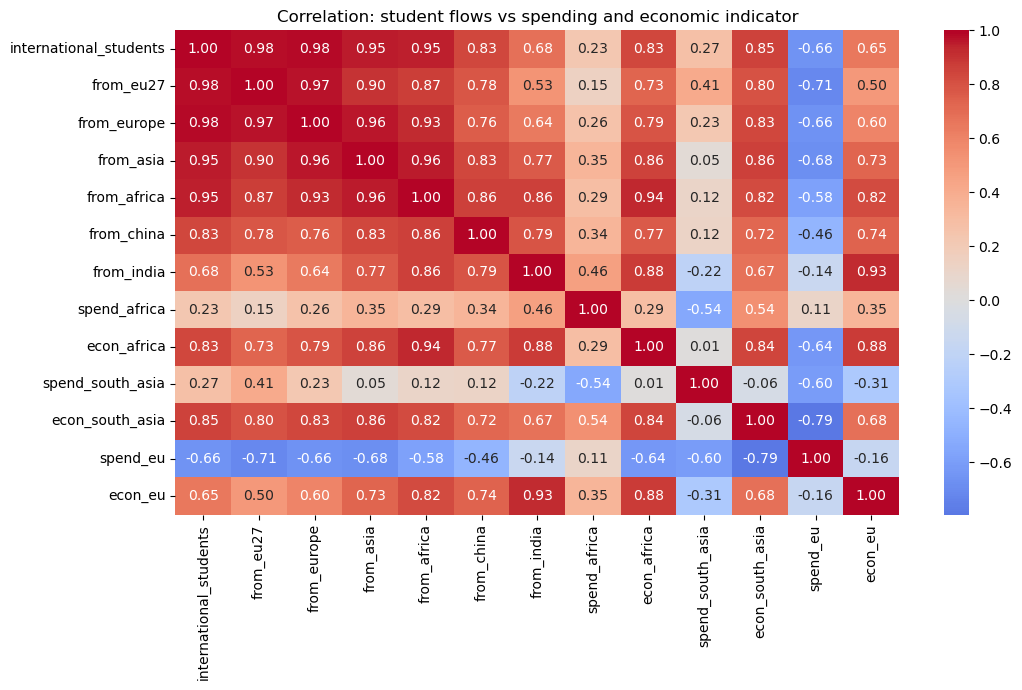

In [18]:
#Correlation 
spend_pairs = [("spend_africa", "from_africa"), ("spend_south_asia", "from_india"),
               ("spend_south_asia", "from_asia"), ("spend_eu", "from_eu27")]
econ_pairs = [("econ_africa", "from_africa"), ("econ_south_asia", "from_india"),
              ("econ_south_asia", "from_asia"), ("econ_eu", "from_eu27")]
all_pairs = spend_pairs + econ_pairs
 
def run_corr(data, label):
    for x, y in all_pairs:
        d = data[[x, y]].dropna()
        if len(d) < 4:
            print(f"{x} vs {y}: only {len(d)} overlapping years - skipped")
            continue
        pr, pp = pearsonr(d[x], d[y])
        sr, sp = spearmanr(d[x], d[y])
        print(f"{x} vs {y} (n={len(d)}): Pearson r={pr:.2f} (p={pp:.3f}) | Spearman rho={sr:.2f} (p={sp:.3f})")
 
print("\n--- Correlation on levels ---")
run_corr(analysis, "levels")
 
# Both series trend over time, so also test year-over-year CHANGES (avoids spurious correlation)
print("\n--- Correlation on year-over-year changes ---")
run_corr(analysis.diff(), "changes")
 
plt.figure(figsize=(11, 7))
sns.heatmap(analysis.drop(columns=["total_growth_pct"]).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation: student flows vs spending and economic indicator")
plt.tight_layout()
plt.show()

In [17]:
#Training the machine 
# 5a. Trend + forecast
print("\n--- ML 1: Linear trend + 3-year forecast ---")
future_years = np.arange(last + 1, last + 4).reshape(-1, 1)
for col in ["international_students", "from_africa", "from_asia", "from_india", "from_eu27"]:
    X = yearly.index.values.reshape(-1, 1)
    y = yearly[col].values
    model = LinearRegression().fit(X, y)
    r2 = r2_score(y, model.predict(X))
    forecast = model.predict(future_years).astype(int)
    print(f"{col}: +{model.coef_[0]:,.0f} students/year | R2={r2:.2f} | forecast {list(future_years.ravel())}: {list(forecast)}")
 
# 5b. One predictor at a time: does a lower value predict more students sent?
print("\n--- ML 2: students sent ~ one predictor ---")
for x, y in spend_pairs[:3] + econ_pairs[:3]:
    d = analysis[[x, y]].dropna()
    if len(d) < 4:
        print(f"{y} ~ {x}: only {len(d)} years - skipped")
        continue
    model = LinearRegression().fit(d[[x]].values, d[y].values)
    r2 = r2_score(d[y].values, model.predict(d[[x]].values))
    direction = "NEGATIVE (supports hypothesis)" if model.coef_[0] < 0 else "POSITIVE (does not support)"
    print(f"{y} ~ {x} (n={len(d)}): coef={model.coef_[0]:,.0f} -> {direction} | R2={r2:.2f}")
 
# 5c. Both predictors together (standardised so coefficients are comparable)
print("\n--- ML 3: students sent ~ spending + economic indicator (standardised) ---")
for y, a, b in [("from_africa", "spend_africa", "econ_africa"),
                ("from_india", "spend_south_asia", "econ_south_asia")]:
    d = analysis[[y, a, b]].dropna()
    if len(d) < 5:
        print(f"{y}: only {len(d)} years - skipped")
        continue
    X = StandardScaler().fit_transform(d[[a, b]])
    model = LinearRegression().fit(X, d[y].values)
    r2 = r2_score(d[y].values, model.predict(X))
    print(f"{y} (n={len(d)}): {a} coef={model.coef_[0]:,.0f} | {b} coef={model.coef_[1]:,.0f} | R2={r2:.2f}")
print("(With very few years, treat these coefficients as indicative only.)")


--- ML 1: Linear trend + 3-year forecast ---
international_students: +200,646 students/year | R2=0.74 | forecast [np.int64(2025), np.int64(2026), np.int64(2027)]: [np.int64(4198244), np.int64(4398890), np.int64(4599536)]
from_africa: +42,825 students/year | R2=0.94 | forecast [np.int64(2025), np.int64(2026), np.int64(2027)]: [np.int64(697468), np.int64(740293), np.int64(783118)]
from_asia: +54,427 students/year | R2=0.83 | forecast [np.int64(2025), np.int64(2026), np.int64(2027)]: [np.int64(1113941), np.int64(1168368), np.int64(1222794)]
from_india: +15,156 students/year | R2=0.88 | forecast [np.int64(2025), np.int64(2026), np.int64(2027)]: [np.int64(181236), np.int64(196392), np.int64(211548)]
from_eu27: +51,593 students/year | R2=0.58 | forecast [np.int64(2025), np.int64(2026), np.int64(2027)]: [np.int64(1187415), np.int64(1239009), np.int64(1290602)]

--- ML 2: students sent ~ one predictor ---
from_africa ~ spend_africa (n=12): coef=158,055 -> POSITIVE (does not support) | R2=0.08

In [21]:
#Verdict on hypothsis 
print("\n=== HYPOTHESIS CHECK ===")
print("1) More students recently?     ->", "YES" if yearly['international_students'].iloc[-1] > yearly['international_students'].iloc[0] else "NO")
top = shares.loc[last, ["from_africa", "from_asia", "from_china", "from_india"]].sort_values(ascending=False)
print("2) Top Asian/African origins in latest year (% of total):\n", top.round(1).to_string())
print("3) Do origin regions have lower spending / lower economic indicator than the EU? -> see gap lines in section 3")
print("4) Do lower values go with more students sent? -> see correlation (levels AND changes) + ML 2 / ML 3")
print("\nCaution: few overlapping years = low statistical power. Correlation is not causation.")
 


=== HYPOTHESIS CHECK ===
1) More students recently?     -> YES
2) Top Asian/African origins in latest year (% of total):
 from_asia      29.0
from_africa    16.9
from_china      5.1
from_india      5.1
3) Do origin regions have lower spending / lower economic indicator than the EU? -> see gap lines in section 3
4) Do lower values go with more students sent? -> see correlation (levels AND changes) + ML 2 / ML 3

Caution: few overlapping years = low statistical power. Correlation is not causation.
